# Weighted Survey Counts

How are recorded respondents distributed by eye colour?

Data: [datasets/HairEyeColor](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/HairEyeColor.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Rows are contingency-table cells; use frequency weights, never row counts as respondent counts.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Weighted Survey Counts',
 'executed_utc': '2026-11-21T10:14:13.690511+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/datasets/HairEyeColor.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/datasets/HairEyeColor.html',
 'sha256': 'c371b0bb7955bad62da375330e626a5dcc7709ca7ec6ee08fb9e58ae4287ec94',
 'raw_rows': 32,
 'analysis_rows': 32,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,32
1,Hair,object,0,0.0,4
2,Eye,object,0,0.0,4
3,Sex,object,0,0.0,2
4,Freq,int64,0,0.0,22


## SQL and analysis
Sum recorded Freq within each Eye category; the row grain is an aggregated cell.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "Eye" AS segment, COUNT(*) AS rows_used, SUM("Freq") AS metric, MIN("Freq") AS minimum, MAX("Freq") AS maximum FROM observations GROUP BY "Eye" ORDER BY "Eye";

The largest observed sum of Freq is 220.000 for Brown. This ranking is descriptive, not a recommendation.


,segment,rows_used,metric,minimum,maximum
0,Blue,8,215,7,64
1,Brown,8,220,3,66
2,Green,8,64,2,15
3,Hazel,8,93,5,29


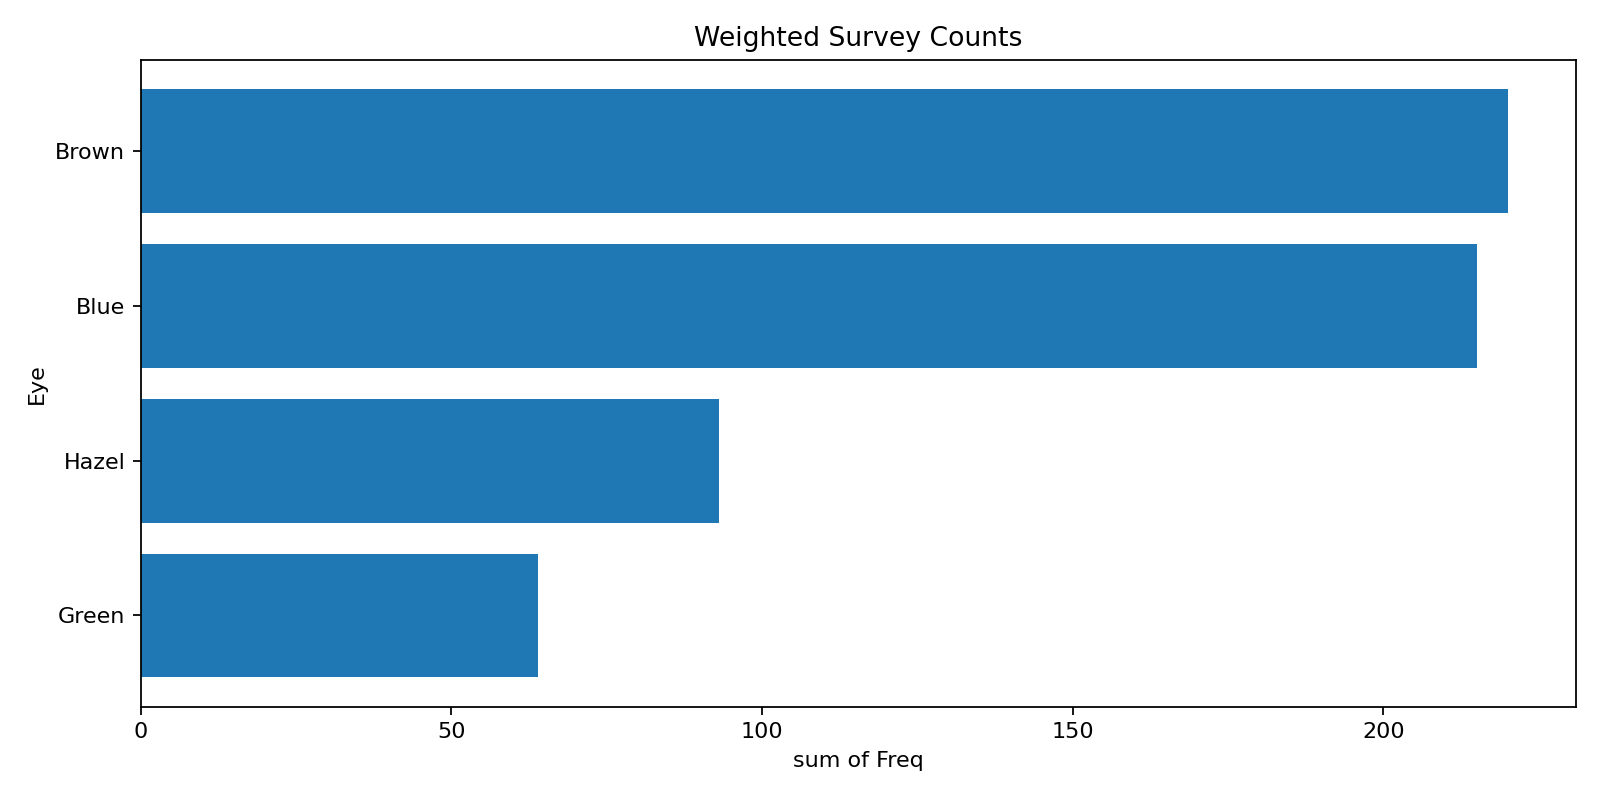

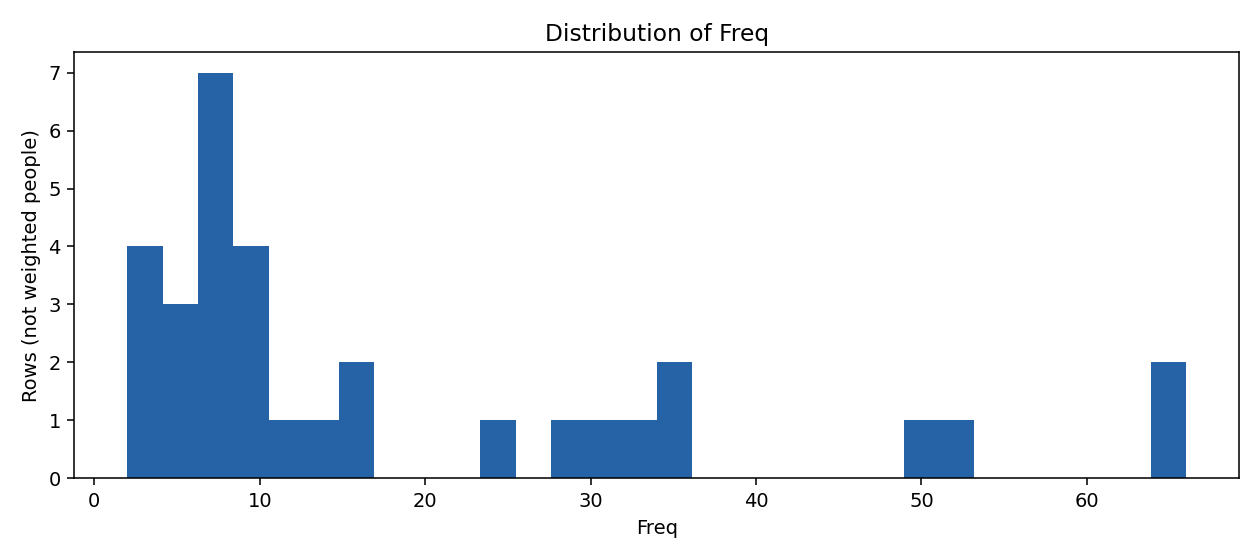

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Rows are contingency-table cells; use frequency weights, never row counts as respondent counts.

**Next action:** Retain weights when cross-tabulating hair colour and sex.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.